# Question
### In Baseball. what is the probability of someone with a 20% batting average getting between 4 and 6 hits out of 15 hits?

# Description
### Random Variable: One hit
### One Trial: hit the ball 15 times with a 20% hit chance
### Possible Outcomes: 0/15, 1/15, 2/15, ..., 14/15, 15/15

# Analisys

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import binom

In [19]:
# Constants
num_trials = 1000
n_swings = 15
p_hit = 0.20
target_hits = [4, 5, 6]

In [20]:
def simulate_hits(num_swings=15, hit_rate=0.20):
    """Simulates a player with a given hit rate swinging at a specified number of balls.

    Returns the total number of hits made in that trial.
    """
    outcomes = np.random.choice(
        [1, 0], size=num_swings, p=[hit_rate, 1 - hit_rate]
    )
    return np.sum(outcomes)

In [21]:
# Run 1000 trials
results = [simulate_hits() for _ in range(num_trials)]
for i in results:
    if (i >= 4 and i <= 6):
        cumulative_relative_frequency = []

# Store trial numbers (1 to 1000) and hit counts in a pandas DataFrame
df_hits = pd.DataFrame(
    {"trial_number": range(1, num_trials + 1), "hits_per_trial": results, }
)

df_hits["cum_rel_freq_4_to_6"] = (
    df_hits["hits_per_trial"].isin([4, 5, 6]).cumsum() / df_hits["trial_number"]
)

# Display the first few rows
print(df_hits.head())

   trial_number  hits_per_trial  cum_rel_freq_4_to_6
0             1               6             1.000000
1             2               4             1.000000
2             3               1             0.666667
3             4               2             0.500000
4             5               2             0.400000


In [35]:
# 1. Theoretical Probability (using Binomial PMF: P(X = 4) + P(X = 5) + P(X = 6))
theoretical_prob = sum(binom.pmf(k, n_swings, p_hit) for k in target_hits)

# 2. Empirical Probability (final cumulative relative frequency from trial 1000)
empirical_prob = df_hits["cum_rel_freq_4_to_6"].iloc[-1]

# Display Results
print(f"Theoretical Probability (4, 5, or 6 hits): {theoretical_prob:.3f}")
print(f"Empirical Probability (1,000 trials):       {empirical_prob:.3f}")

Theoretical Probability (4, 5, or 6 hits): 0.334
Empirical Probability (1,000 trials):       0.331


In [36]:
# 1. Theoretical Mean and Standard Deviation (Binomial Distribution)
# Mean: E[X] = n * p
theoretical_mean = n_swings * p_hit

# Standard Deviation: SD = sqrt(n * p * (1 - p))
theoretical_std = np.sqrt(n_swings * p_hit * (1 - p_hit))

# 2. Empirical Mean and Standard Deviation (from 1,000 trials)
empirical_mean = df_hits["hits_per_trial"].mean()
empirical_std = df_hits["hits_per_trial"].std()

# Display Results
print("--- Mean ---")
print(f"Theoretical Mean: {theoretical_mean:.3f}")
print(f"Empirical Mean:   {empirical_mean:.3f}")

print("\n--- Standard Deviation ---")
print(f"Theoretical Std:  {theoretical_std:.3f}")
print(f"Empirical Std:    {empirical_std:.3f}")

--- Mean ---
Theoretical Mean: 3.000
Empirical Mean:   3.035

--- Standard Deviation ---
Theoretical Std:  1.549
Empirical Std:    1.572


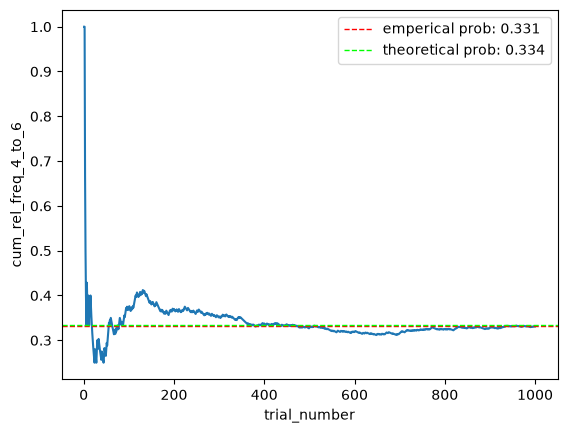

In [37]:
sns.lineplot(data=df_hits, x=df_hits["trial_number"], y=df_hits["cum_rel_freq_4_to_6"])
plt.axhline(empirical_prob, color="red", linestyle="--", linewidth="1", label=f"emperical prob: {empirical_prob}")
plt.axhline(theoretical_prob, color="lime", linestyle="--", linewidth="1", label=f"theoretical prob: {theoretical_prob:.3f}")
plt.legend()

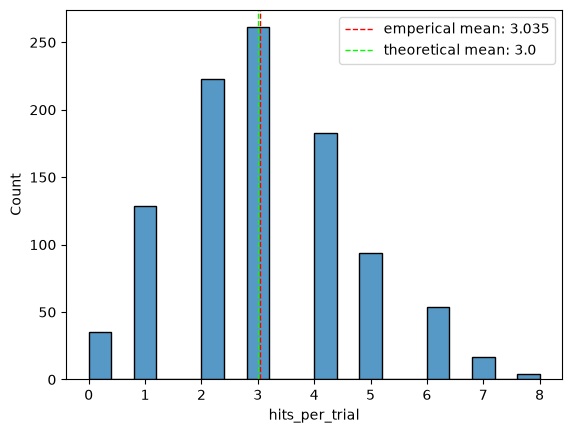

In [38]:
sns.histplot(data=df_hits, x=df_hits["hits_per_trial"])
plt.axvline(empirical_mean, color="red", linestyle="--", linewidth="1", label=f"emperical mean: {empirical_mean}")
plt.axvline(theoretical_mean, color="lime", linestyle="--", linewidth="1", label=f"theoretical mean: {theoretical_mean}")
plt.legend()

# Conclusion:

<!-- theoretical and emperical probs -->